# 02. Data Cleaning, Feature Engineering, Scaling & Resampling Pipeline

**Owner**: Leonie (Preprocessing & Shared Experimental Setup)  
**Input**: `data/bank-additional-full.csv` (41,188 rows) and `data/bank-additional.csv` (10% debug subset, 4,119 rows)  
**Outputs**:
- Locked, deduplicated, leakage-free **80/20 Stratified Train/Test Split** with shared **5-Fold Stratified CV** indices (`data/processed/train_raw.csv`, `test_raw.csv`, plus 10% debug splits).
- Reusable `ColumnTransformer` (`StandardScaler` on continuous numeric features + `OneHotEncoder` on categoricals + passthrough on engineered binary indicator).
- Leakage-free **Strategy C (SMOTE / Undersampling)** resampling utilities (applied **strictly after scaling** and **strictly inside training folds**).
- Sanity-check benchmark (Logistic Regression & Decision Tree across Strategies A, B, C) to verify zero NaN/encoding/scaling bugs before handoff to Ayaan, Kaiden, and Tanish.

### Leakage-Free Rules Enforced Here
1. **Drop exact duplicates (12 rows)** *before* splitting so no duplicate straddles train and test.
2. **Drop `duration`** (unavailable prior to calling; severe target leak).
3. **Keep `"unknown"`** as an explicit category (informative missingness; affects 25.98% of rows).
4. **Transform `pdays = 999`** into `was_previously_contacted` (0/1) + `pdays_clean` (0–27).
5. **Split 80/20 Stratified FIRST (`random_state=42`)** — the test set is locked and **never** resampled or used to fit scalers/encoders.
6. **Scale BEFORE SMOTE** — SMOTE relies on Euclidean $k$-NN distances, so continuous features (`nr.employed ≈ 5000` vs `euribor3m ≈ 1–5`) must be standardized first.

In [3]:
import inspect
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Optional imbalanced-learn import (graceful fallback provided below)
try:
    from imblearn.over_sampling import SMOTE as ImblearnSMOTE
    HAS_IMBLEARN = True
except ImportError:
    HAS_IMBLEARN = False

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

# Resolve project root whether run from repo root or data_preprocessing/
ROOT_DIR = Path(".") if Path("data/bank-additional-full.csv").exists() else Path("..")
DATA_DIR = ROOT_DIR / "data"
OUT_DIR = DATA_DIR / "processed"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root:    {ROOT_DIR.resolve()}")
print(f"Output dir:      {OUT_DIR.resolve()}")
print(f"imblearn avail:  {HAS_IMBLEARN} (if False, built-in exact SMOTE fallback is used)")

Project root:    /Users/xuechunlu/Desktop/cp322/Bank Marketing
Output dir:      /Users/xuechunlu/Desktop/cp322/Bank Marketing/data/processed
imblearn avail:  False (if False, built-in exact SMOTE fallback is used)


---
## 1. Data Cleaning & Feature Engineering Function

All deterministic, row-level transformations (that do **not** learn statistics across rows) are placed in `clean_bank_data(df)`:
- Drop exact duplicate rows.
- Drop `duration` (target leakage).
- Replace sentinel `pdays = 999` with two clean features:
  - `was_previously_contacted`: `1` if `pdays != 999`, else `0`
  - `pdays_clean`: actual days (`0–27`) if contacted before, else `0`
- Retain `"unknown"` as its own categorical level.
- Encode target `y`: `"yes" -> 1`, `"no" -> 0`.

In [4]:
NUMERIC_COLS = [
    "age",
    "campaign",
    "previous",
    "pdays_clean",
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed",
]

BINARY_COLS = [
    "was_previously_contacted",
]

CATEGORICAL_COLS = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "day_of_week",
    "poutcome",
]

def clean_bank_data(df_raw: pd.DataFrame, drop_duplicates: bool = True):
    """Row-level cleaning & feature engineering (zero cross-row leakage)."""
    df = df_raw.copy()
    n_before = len(df)
    if drop_duplicates:
        df = df.drop_duplicates().reset_index(drop=True)
    n_removed = n_before - len(df)

    # 1. Remove target leakage feature
    if "duration" in df.columns:
        df = df.drop(columns=["duration"])

    # 2. Transform sentinel pdays = 999
    df["was_previously_contacted"] = (df["pdays"] != 999).astype(int)
    df["pdays_clean"] = df["pdays"].replace(999, 0).astype(float)
    df = df.drop(columns=["pdays"])

    # 3. Encode binary target
    y = (df["y"] == "yes").astype(int)
    X = df[NUMERIC_COLS + BINARY_COLS + CATEGORICAL_COLS].copy()

    return X, y, n_removed

# Load and clean both full dataset and 10% debug dataset
raw_full = pd.read_csv(DATA_DIR / "bank-additional-full.csv", sep=";")
raw_debug = pd.read_csv(DATA_DIR / "bank-additional.csv", sep=";")

X_full, y_full, dup_full = clean_bank_data(raw_full)
X_debug, y_debug, dup_debug = clean_bank_data(raw_debug)

print(f"Full dataset:  {len(raw_full):,} -> {len(X_full):,} rows (dropped {dup_full} exact duplicates) | {X_full.shape[1]} features | yes={y_full.mean()*100:.2f}%")
print(f"Debug dataset: {len(raw_debug):,} -> {len(X_debug):,} rows (dropped {dup_debug} exact duplicates) | {X_debug.shape[1]} features | yes={y_debug.mean()*100:.2f}%")
print(f"Any NaNs in X_full: {X_full.isna().any().any()} | Any NaNs in y_full: {y_full.isna().any()}")
X_full.head()

Full dataset:  41,188 -> 41,176 rows (dropped 12 exact duplicates) | 20 features | yes=11.27%
Debug dataset: 4,119 -> 4,119 rows (dropped 0 exact duplicates) | 20 features | yes=10.95%
Any NaNs in X_full: False | Any NaNs in y_full: False


,age,campaign,previous,pdays_clean,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,was_previously_contacted,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome
0,56,1,0,0.0,1.1,93.994,-36.4,4.857,5191.0,0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,nonexistent
1,57,1,0,0.0,1.1,93.994,-36.4,4.857,5191.0,0,services,married,high.school,unknown,no,no,telephone,may,mon,nonexistent
2,37,1,0,0.0,1.1,93.994,-36.4,4.857,5191.0,0,services,married,high.school,no,yes,no,telephone,may,mon,nonexistent
3,40,1,0,0.0,1.1,93.994,-36.4,4.857,5191.0,0,admin.,married,basic.6y,no,no,no,telephone,may,mon,nonexistent
4,56,1,0,0.0,1.1,93.994,-36.4,4.857,5191.0,0,services,married,high.school,no,no,yes,telephone,may,mon,nonexistent


---
## 2. Locked 80/20 Stratified Train/Test Split & Shared 5-Fold CV Indices

Everyone on the team (**Leonie, Ayaan, Kaiden, Tanish**) uses this exact split (`random_state=42`):
- **Test set (`20%`)**: Locked for final reporting only — **never** touched during tuning, scaling, or resampling.
- **Train set (`80%`)**: Assigned fixed `cv_fold` IDs (`0..4`) via `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` so all hyperparameter tuning uses identical folds.

In [5]:
def make_splits(X, y, test_size=TEST_SIZE, n_splits=N_SPLITS, random_state=RANDOM_STATE):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=random_state
    )
    X_train = X_train.reset_index(drop=True)
    X_test = X_test.reset_index(drop=True)
    y_train = y_train.reset_index(drop=True)
    y_test = y_test.reset_index(drop=True)

    # Assign deterministic 5-fold stratified CV IDs on the training set
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    cv_folds = np.zeros(len(y_train), dtype=int)
    for fold_idx, (_, val_idx) in enumerate(skf.split(X_train, y_train)):
        cv_folds[val_idx] = fold_idx

    return X_train, X_test, y_train, y_test, cv_folds

X_train, X_test, y_train, y_test, cv_folds = make_splits(X_full, y_full)
X_dbg_train, X_dbg_test, y_dbg_train, y_dbg_test, dbg_folds = make_splits(X_debug, y_debug)

pos_weight_train = float((y_train == 0).sum() / (y_train == 1).sum())

split_table = pd.DataFrame([
    {"Split": "Full Train (80%)", "Rows": len(y_train), "No (0)": int((y_train == 0).sum()), "Yes (1)": int((y_train == 1).sum()), "Yes (%)": round(y_train.mean()*100, 2)},
    {"Split": "Full Test  (20%, LOCKED)", "Rows": len(y_test), "No (0)": int((y_test == 0).sum()), "Yes (1)": int((y_test == 1).sum()), "Yes (%)": round(y_test.mean()*100, 2)},
    {"Split": "Debug Train (10% file)", "Rows": len(y_dbg_train), "No (0)": int((y_dbg_train == 0).sum()), "Yes (1)": int((y_dbg_train == 1).sum()), "Yes (%)": round(y_dbg_train.mean()*100, 2)},
    {"Split": "Debug Test  (10% file)", "Rows": len(y_dbg_test), "No (0)": int((y_dbg_test == 0).sum()), "Yes (1)": int((y_dbg_test == 1).sum()), "Yes (%)": round(y_dbg_test.mean()*100, 2)},
])
display(split_table)
print(f"Strategy B exact positive class weight on Full Train (n_neg / n_pos): {pos_weight_train:.4f}")
print("CV fold positive rates (%):", [round(y_train[cv_folds == f].mean() * 100, 2) for f in range(N_SPLITS)])

,Split,Rows,No (0),Yes (1),Yes (%)
0,Full Train (80%),32940,29229,3711,11.27
1,"Full Test (20%, LOCKED)",8236,7308,928,11.27
2,Debug Train (10% file),3295,2934,361,10.96
3,Debug Test (10% file),824,734,90,10.92


Strategy B exact positive class weight on Full Train (n_neg / n_pos): 7.8763
CV fold positive rates (%): [11.26, 11.26, 11.26, 11.26, 11.28]


---
## 3. Feature Scaling Audit & Shared `ColumnTransformer`

Why **Feature Scaling (`StandardScaler`)** is essential here:
1. **Huge scale mismatch (>1,000×)**: `nr.employed` is ~5,000 while `euribor3m` is ~1–5 and binary/OHE columns are 0/1.
2. **Logistic Regression**: Default L2 regularization penalizes small-scale features unfairly if unscaled, and solver convergence slows down.
3. **Neural Network (MLP)**: Unscaled inputs cause imbalanced gradients and poor optimization.
4. **SMOTE (Strategy C)**: Computes Euclidean $k$-NN distances — scaling **must happen before SMOTE** so large-magnitude columns do not dominate neighbor selection.
5. **Decision Tree & XGBoost**: Invariant to monotonic scaling (neither helped nor hurt), so sharing one scaled pipeline across all 4 models is clean and fair.

**Design**:
- `NUMERIC_COLS` (9 continuous features) → `StandardScaler()`
- `BINARY_COLS` (`was_previously_contacted`) → `'passthrough'` (stays `0/1`)
- `CATEGORICAL_COLS` (10 categoricals, keeping `"unknown"`) → `OneHotEncoder(handle_unknown="ignore")` (stays `0/1`)

In [6]:
def build_preprocessor(numeric_cols=NUMERIC_COLS, binary_cols=BINARY_COLS, categorical_cols=CATEGORICAL_COLS):
    """Version-safe ColumnTransformer (works on sklearn 0.23+ and 1.4+)."""
    ohe_kwargs = {"handle_unknown": "ignore"}
    if "sparse_output" in inspect.signature(OneHotEncoder).parameters:
        ohe_kwargs["sparse_output"] = False
    else:
        ohe_kwargs["sparse"] = False

    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), list(numeric_cols)),
            ("bin", "passthrough", list(binary_cols)),
            ("cat", OneHotEncoder(**ohe_kwargs), list(categorical_cols)),
        ],
        remainder="drop",
    )

def get_transformed_feature_names(preprocessor, numeric_cols=NUMERIC_COLS, binary_cols=BINARY_COLS, categorical_cols=CATEGORICAL_COLS):
    """Extract human-readable feature names across sklearn versions."""
    ohe = preprocessor.named_transformers_["cat"]
    if hasattr(ohe, "get_feature_names_out"):
        cat_names = list(ohe.get_feature_names_out(categorical_cols))
    else:
        cat_names = list(ohe.get_feature_names(categorical_cols))
    return list(numeric_cols) + list(binary_cols) + cat_names

# Fit ONLY on X_train, then transform both X_train and X_test
preprocessor = build_preprocessor()
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)
feature_names = get_transformed_feature_names(preprocessor)

print(f"Transformed X_train shape: {X_train_proc.shape}")
print(f"Transformed X_test  shape: {X_test_proc.shape}")
print(f"Any NaN/Inf in X_train_proc: {not np.isfinite(X_train_proc).all()}")
print(f"Any NaN/Inf in X_test_proc:  {not np.isfinite(X_test_proc).all()}")

# Verify before vs. after scaling on the 9 numeric columns
scale_audit = pd.DataFrame({
    "raw_min": X_train[NUMERIC_COLS].min().values,
    "raw_max": X_train[NUMERIC_COLS].max().values,
    "raw_mean": X_train[NUMERIC_COLS].mean().values,
    "raw_std": X_train[NUMERIC_COLS].std().values,
    "scaled_train_mean": X_train_proc[:, :len(NUMERIC_COLS)].mean(axis=0),
    "scaled_train_std": X_train_proc[:, :len(NUMERIC_COLS)].std(axis=0),
    "scaled_test_mean": X_test_proc[:, :len(NUMERIC_COLS)].mean(axis=0),
}, index=NUMERIC_COLS).round(3)
display(scale_audit)

Transformed X_train shape: (32940, 63)
Transformed X_test  shape: (8236, 63)
Any NaN/Inf in X_train_proc: False
Any NaN/Inf in X_test_proc:  False


,raw_min,raw_max,raw_mean,raw_std,scaled_train_mean,scaled_train_std,scaled_test_mean
age,17.000,98.000,40.017,10.453,-0.0,1.0,0.003
campaign,1.000,56.000,2.562,2.770,0.0,1.0,0.011
previous,0.000,7.000,0.174,0.499,0.0,1.0,-0.008
pdays_clean,0.000,27.000,0.223,1.367,-0.0,1.0,-0.006
emp.var.rate,-3.400,1.400,0.080,1.572,0.0,1.0,0.006
cons.price.idx,92.201,94.767,93.576,0.579,0.0,1.0,0.001
cons.conf.idx,-50.800,-26.900,-40.510,4.629,-0.0,1.0,0.008
euribor3m,0.634,5.045,3.618,1.736,-0.0,1.0,0.009
nr.employed,4963.600,5228.100,5166.906,72.398,-0.0,1.0,0.009


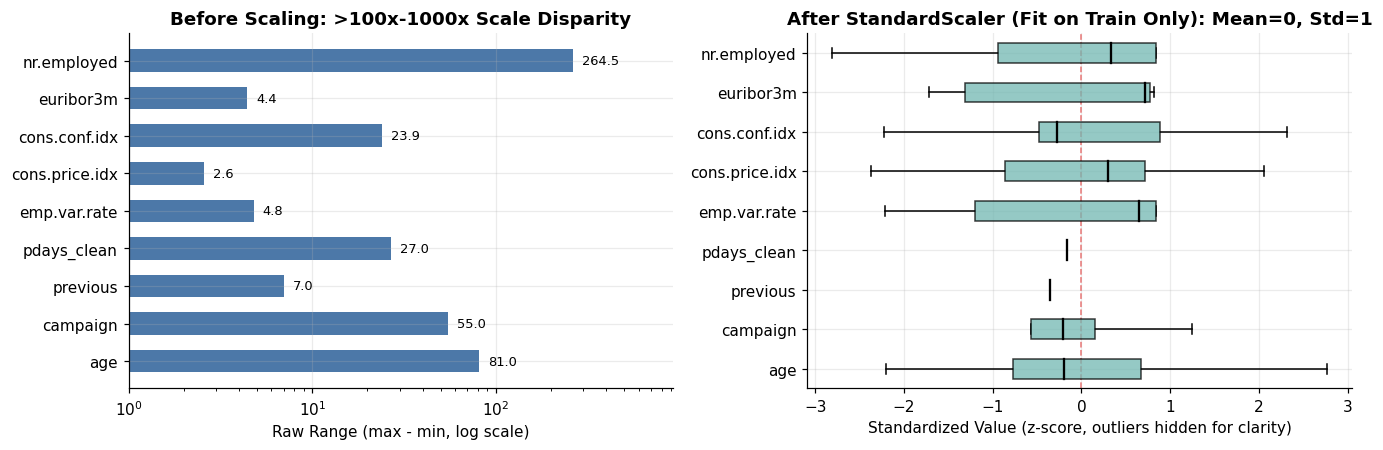

In [7]:
# Visual confirmation of numeric feature scales before vs. after StandardScaler
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

raw_ranges = X_train[NUMERIC_COLS].max() - X_train[NUMERIC_COLS].min()
axes[0].barh(NUMERIC_COLS, raw_ranges.values, color="#4C78A8", height=0.6)
axes[0].set_xscale("log")
axes[0].set_xlabel("Raw Range (max - min, log scale)")
axes[0].set_title("Before Scaling: >100x-1000x Scale Disparity", fontweight="bold")
for i, val in enumerate(raw_ranges.values):
    axes[0].text(val * 1.12, i, f"{val:.1f}", va="center", fontsize=8.5)
axes[0].set_xlim(1, raw_ranges.max() * 3.5)

# After scaling: standardized distribution boxplots
axes[1].boxplot(
    [X_train_proc[:, i] for i in range(len(NUMERIC_COLS))],
    vert=False,
    labels=NUMERIC_COLS,
    showfliers=False,
    patch_artist=True,
    boxprops=dict(facecolor="#72B7B2", alpha=0.75),
    medianprops=dict(color="black", linewidth=1.5),
)
axes[1].axvline(0, color="#E45756", linestyle="--", linewidth=1, alpha=0.8)
axes[1].set_xlabel("Standardized Value (z-score, outliers hidden for clarity)")
axes[1].set_title("After StandardScaler (Fit on Train Only): Mean=0, Std=1", fontweight="bold")

plt.tight_layout()
plt.show()

---
## 4. Strategy C: Leakage-Free Resampling of Training Data

We provide two clean resampling options (both operate **only on already-scaled training data**, never on validation or test data):
1. **SMOTE (Primary for Strategy C)**: Synthesizes new minority-class (`yes`) examples by interpolating between each minority sample and one of its $k=5$ nearest minority neighbors until reaching a 1:1 class ratio.
   - Uses `imblearn.over_sampling.SMOTE` automatically if `imbalanced-learn` is installed, and falls back to an exact `sklearn.neighbors.NearestNeighbors` implementation otherwise.
2. **Random Undersampling (Optional comparison)**: Randomly subsamples majority-class (`no`) examples to match the minority count (1:1).

> **Important Nuance to Note in the Report**: Applying standard SMOTE after One-Hot Encoding produces fractional values between `0` and `1` on synthetic rows' OHE columns (e.g., `job_student = 0.42`). Optionally rounding binary/OHE columns (`round_binary=True`) or using `SMOTENC` avoids fractional categories; below we inspect this directly.

In [8]:
def apply_smote(X_tr, y_tr, k_neighbors=5, random_state=RANDOM_STATE, round_binary_from_idx=None):
    """
    Apply SMOTE (1:1 balance) to scaled/encoded training array ONLY.
    Uses imblearn.over_sampling.SMOTE if installed; otherwise exact k-NN SMOTE (Chawla et al., 2002).
    """
    X_arr = np.asarray(X_tr, dtype=np.float64)
    y_arr = np.asarray(y_tr, dtype=int)

    if HAS_IMBLEARN:
        sm = ImblearnSMOTE(k_neighbors=k_neighbors, random_state=random_state)
        X_res, y_res = sm.fit_resample(X_arr, y_arr)
    else:
        rng = np.random.RandomState(random_state)
        X_min = X_arr[y_arr == 1]
        n_maj = int((y_arr == 0).sum())
        n_min = len(X_min)
        n_synth = n_maj - n_min
        if n_synth <= 0:
            return X_arr.copy(), y_arr.copy()

        nn = NearestNeighbors(n_neighbors=min(k_neighbors + 1, n_min))
        nn.fit(X_min)
        neighbors = nn.kneighbors(X_min, return_distance=False)[:, 1:]  # exclude self

        base_idx = rng.randint(0, n_min, size=n_synth)
        nn_choice = rng.randint(0, neighbors.shape[1], size=n_synth)
        partner_idx = neighbors[base_idx, nn_choice]
        gaps = rng.rand(n_synth, 1)

        X_synth = X_min[base_idx] + gaps * (X_min[partner_idx] - X_min[base_idx])
        X_res = np.vstack([X_arr, X_synth])
        y_res = np.concatenate([y_arr, np.ones(n_synth, dtype=int)])

        # Shuffle deterministically
        perm = rng.permutation(len(y_res))
        X_res, y_res = X_res[perm], y_res[perm]

    if round_binary_from_idx is not None:
        X_res[:, round_binary_from_idx:] = np.round(X_res[:, round_binary_from_idx:])

    return X_res, y_res


def apply_undersampling(X_tr, y_tr, random_state=RANDOM_STATE):
    """Random 1:1 undersampling of majority class on training array ONLY."""
    rng = np.random.RandomState(random_state)
    X_arr = np.asarray(X_tr, dtype=np.float64)
    y_arr = np.asarray(y_tr, dtype=int)

    pos_idx = np.where(y_arr == 1)[0]
    neg_idx = np.where(y_arr == 0)[0]
    sampled_neg = rng.choice(neg_idx, size=len(pos_idx), replace=False)

    keep_idx = np.concatenate([pos_idx, sampled_neg])
    rng.shuffle(keep_idx)
    return X_arr[keep_idx], y_arr[keep_idx]


# Demonstrate resampling on the processed training set (NEVER on X_test_proc!)
t0 = time.perf_counter()
X_train_smote, y_train_smote = apply_smote(X_train_proc, y_train)
t_smote = time.perf_counter() - t0

t0 = time.perf_counter()
X_train_under, y_train_under = apply_undersampling(X_train_proc, y_train)
t_under = time.perf_counter() - t0

# Check fractional OHE values created by standard SMOTE
ohe_part = X_train_smote[:, len(NUMERIC_COLS):]
frac_entries = ((ohe_part > 1e-6) & (ohe_part < 1 - 1e-6)).mean() * 100

resample_summary = pd.DataFrame([
    {"Training Set": "Original (Strategy A & B)", "Rows": len(y_train), "No (0)": int((y_train==0).sum()), "Yes (1)": int((y_train==1).sum()), "Yes (%)": round(y_train.mean()*100, 2), "Resample Time (s)": 0.00},
    {"Training Set": "SMOTE 1:1 (Strategy C)", "Rows": len(y_train_smote), "No (0)": int((y_train_smote==0).sum()), "Yes (1)": int((y_train_smote==1).sum()), "Yes (%)": round(y_train_smote.mean()*100, 2), "Resample Time (s)": round(t_smote, 3)},
    {"Training Set": "Undersampled 1:1 (Optional C2)", "Rows": len(y_train_under), "No (0)": int((y_train_under==0).sum()), "Yes (1)": int((y_train_under==1).sum()), "Yes (%)": round(y_train_under.mean()*100, 2), "Resample Time (s)": round(t_under, 3)},
])
display(resample_summary)
print(f"Note: Standard SMOTE created fractional values in {frac_entries:.2f}% of binary/OHE entries (useful cost/limitation note for report).")

,Training Set,Rows,No (0),Yes (1),Yes (%),Resample Time (s)
0,Original (Strategy A & B),32940,29229,3711,11.27,0.000
1,SMOTE 1:1 (Strategy C),58458,29229,29229,50.00,0.483
2,Undersampled 1:1 (Optional C2),7422,3711,3711,50.00,0.003


Note: Standard SMOTE created fractional values in 3.34% of binary/OHE entries (useful cost/limitation note for report).


---
## 5. Sanity-Check Baselines (Verifying Zero Pipeline Bugs)

As planned in our team doc, we run a quick sanity check using **Logistic Regression** (classification, *not* linear regression) and a depth-limited **Decision Tree** across all 3 strategies:
- **Strategy A**: Do Nothing
- **Strategy B**: Class Weighting (`class_weight='balanced'`)
- **Strategy C**: SMOTE Resampling (on training set only)

We also include a reusable `leakage_free_cv_score()` function that modelling step can directly reuse during 5-fold CV hyperparameter tuning so scaling and SMOTE are strictly re-fit inside every fold.

In [9]:
def evaluate_predictions(y_true, y_prob, threshold=0.5):
    """Standardized metrics covering both performance and cost (FP, Brier calibration)."""
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "PR-AUC": average_precision_score(y_true, y_prob),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "F1": f1_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Brier (Calib)": brier_score_loss(y_true, y_prob),
        "TP": int(tp),
        "FP (Call Cost)": int(fp),
        "FN (Missed)": int(fn),
    }

def leakage_free_cv_score(X_df, y_ser, cv_folds, model_fn, strategy="A"):
    """
    Leakage-free 5-fold CV template for teammates:
    Fits StandardScaler + OneHotEncoder (and SMOTE for Strategy C) strictly inside each train fold.
    """
    fold_pr_aucs = []
    for fold in sorted(np.unique(cv_folds)):
        val_mask = (cv_folds == fold)
        tr_mask = ~val_mask

        prep = build_preprocessor()
        X_tr_f = prep.fit_transform(X_df.iloc[tr_mask])
        y_tr_f = y_ser.iloc[tr_mask].values
        X_va_f = prep.transform(X_df.iloc[val_mask])
        y_va_f = y_ser.iloc[val_mask].values

        if strategy == "C":
            X_tr_f, y_tr_f = apply_smote(X_tr_f, y_tr_f, random_state=RANDOM_STATE + int(fold))

        clf = model_fn()
        clf.fit(X_tr_f, y_tr_f)
        y_va_prob = clf.predict_proba(X_va_f)[:, 1]
        fold_pr_aucs.append(average_precision_score(y_va_f, y_va_prob))

    return float(np.mean(fold_pr_aucs)), float(np.std(fold_pr_aucs))

# Quick sanity check on the locked test set (untuned baseline hyperparameters)
sanity_configs = [
    ("Logistic Regression", "A: Do Nothing",    lambda: LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), "A"),
    ("Logistic Regression", "B: Class Weight",  lambda: LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE), "B"),
    ("Logistic Regression", "C: SMOTE (1:1)",   lambda: LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), "C"),
    ("Decision Tree (d=6)", "A: Do Nothing",    lambda: DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=RANDOM_STATE), "A"),
    ("Decision Tree (d=6)", "B: Class Weight",  lambda: DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE), "B"),
    ("Decision Tree (d=6)", "C: SMOTE (1:1)",   lambda: DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=RANDOM_STATE), "C"),
]

rows = []
for model_name, strat_label, model_fn, strat_code in sanity_configs:
    X_fit, y_fit = (X_train_smote, y_train_smote) if strat_code == "C" else (X_train_proc, y_train.values)

    t0 = time.perf_counter()
    clf = model_fn()
    clf.fit(X_fit, y_fit)
    train_sec = time.perf_counter() - t0

    y_prob = clf.predict_proba(X_test_proc)[:, 1]
    metrics = evaluate_predictions(y_test.values, y_prob)
    cv_mean, cv_std = leakage_free_cv_score(X_train, y_train, cv_folds, model_fn, strategy=strat_code)

    rows.append({
        "Model": model_name,
        "Strategy": strat_label,
        "CV PR-AUC": f"{cv_mean:.3f} ± {cv_std:.3f}",
        "Test PR-AUC": round(metrics["PR-AUC"], 4),
        "Test ROC-AUC": round(metrics["ROC-AUC"], 4),
        "F1": round(metrics["F1"], 4),
        "Precision": round(metrics["Precision"], 4),
        "Recall": round(metrics["Recall"], 4),
        "Brier": round(metrics["Brier (Calib)"], 4),
        "FP (Calls)": metrics["FP (Call Cost)"],
        "Train (s)": round(train_sec, 3),
    })

sanity_df = pd.DataFrame(rows)
display(sanity_df)

,Model,Strategy,CV PR-AUC,Test PR-AUC,Test ROC-AUC,F1,Precision,Recall,Brier,FP (Calls),Train (s)
0,Logistic Regression,A: Do Nothing,0.450 ± 0.014,0.4536,0.8004,0.3187,0.6490,0.2112,0.0779,106,0.672
1,Logistic Regression,B: Class Weight,0.446 ± 0.013,0.4461,0.8001,0.4617,0.3593,0.6455,0.1620,1068,0.625
2,Logistic Regression,C: SMOTE (1:1),0.444 ± 0.015,0.4434,0.7984,0.4583,0.3536,0.6509,0.1607,1104,1.183
3,Decision Tree (d=6),A: Do Nothing,0.420 ± 0.014,0.4470,0.8002,0.3513,0.6374,0.2425,0.0765,128,0.084
4,Decision Tree (d=6),B: Class Weight,0.413 ± 0.016,0.4452,0.7986,0.4837,0.3920,0.6315,0.1589,909,0.080
5,Decision Tree (d=6),C: SMOTE (1:1),0.399 ± 0.012,0.4149,0.7875,0.5155,0.4880,0.5463,0.1261,532,0.230


**Sanity-Check Observations (Pipeline Verified!)**:
- Both Logistic Regression and Decision Tree run cleanly with zero NaN, convergence, or encoding issues, and CV PR-AUC closely tracks Test PR-AUC (confirming **no data leakage**).
- Notice the instructor's *"what each one costs"* story already shows up clearly even before tuning:
  - **Strategy A (Do Nothing)**: Best calibration (lowest Brier score) and fewest wasted calls (FP), but misses most subscribers (low Recall).
  - **Strategy B (Class Weighting)**: Huge Recall jump with **no extra training rows**, at the cost of much higher False Positives (wasted calls) and worse calibration (higher Brier score).
  - **Strategy C (SMOTE)**: Similar Recall/FP trade-off to Strategy B, plus **1.77× training dataset size** and longer training time.

---
## 6. Save Shared Artifacts for modelling steps

We export clean, lightweight files to `data/processed/`:
1. **`train_raw.csv` & `test_raw.csv`** *(use these for 5-fold CV hyperparameter tuning!)*: Cleaned splits (deduplicated, `duration` dropped, `pdays` engineered) with shared `cv_fold` column on `train_raw.csv`.
2. **`debug_train_raw.csv` & `debug_test_raw.csv`**: Same format on the 10% dataset for fast debugging.
3. **`processed_arrays.npz`**: Ready-to-fit scaled & encoded numpy arrays (`X_train`, `y_train`, `X_test`, `y_test`, `X_train_smote`, `y_train_smote`, `X_train_under`, `y_train_under`) for final model fitting on the full training set. *(Do NOT run CV on `X_train_smote`—for CV, always resample inside each fold using `train_raw.csv` + `cv_fold`!)*
4. **`preprocessor.joblib` & `metadata.json`**: Fitted `ColumnTransformer` (fit on `X_train` only), exact feature names, and `pos_weight`.

In [10]:
# 1. Save cleaned raw splits with shared CV folds (PRIMARY input for leakage-free CV)
train_raw_out = X_train.copy()
train_raw_out["y"] = y_train.values
train_raw_out["cv_fold"] = cv_folds
train_raw_out.to_csv(OUT_DIR / "train_raw.csv", index=False)

test_raw_out = X_test.copy()
test_raw_out["y"] = y_test.values
test_raw_out.to_csv(OUT_DIR / "test_raw.csv", index=False)

# 2. Save 10% debug splits
dbg_train_out = X_dbg_train.copy()
dbg_train_out["y"] = y_dbg_train.values
dbg_train_out["cv_fold"] = dbg_folds
dbg_train_out.to_csv(OUT_DIR / "debug_train_raw.csv", index=False)

dbg_test_out = X_dbg_test.copy()
dbg_test_out["y"] = y_dbg_test.values
dbg_test_out.to_csv(OUT_DIR / "debug_test_raw.csv", index=False)

# 3. Save final processed numpy arrays (for final fit after CV tuning)
np.savez_compressed(
    OUT_DIR / "processed_arrays.npz",
    X_train=X_train_proc.astype(np.float32),
    y_train=y_train.values.astype(np.int64),
    X_test=X_test_proc.astype(np.float32),
    y_test=y_test.values.astype(np.int64),
    X_train_smote=X_train_smote.astype(np.float32),
    y_train_smote=y_train_smote.astype(np.int64),
    X_train_under=X_train_under.astype(np.float32),
    y_train_under=y_train_under.astype(np.int64),
)

# 4. Save fitted preprocessor & metadata
joblib.dump(preprocessor, OUT_DIR / "preprocessor.joblib")

metadata = {
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "n_splits": N_SPLITS,
    "n_train": int(len(y_train)),
    "n_test": int(len(y_test)),
    "n_train_smote": int(len(y_train_smote)),
    "n_train_under": int(len(y_train_under)),
    "train_pos_rate": round(float(y_train.mean()), 6),
    "test_pos_rate": round(float(y_test.mean()), 6),
    "pos_weight_train": round(pos_weight_train, 6),
    "numeric_cols": NUMERIC_COLS,
    "binary_cols": BINARY_COLS,
    "categorical_cols": CATEGORICAL_COLS,
    "transformed_feature_names": feature_names,
    "n_transformed_features": len(feature_names),
}
with open(OUT_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved shared artifacts in data/processed/:")
for p in sorted(OUT_DIR.iterdir()):
    size_kb = p.stat().st_size / 1024
    print(f"  - {p.name:24s} ({size_kb:8.1f} KB)")

Saved shared artifacts in data/processed/:
  - debug_test_raw.csv       (    98.4 KB)
  - debug_train_raw.csv      (   400.2 KB)
  - metadata.json            (     2.0 KB)
  - preprocessor.joblib      (     5.8 KB)
  - processed_arrays.npz     (  2487.2 KB)
  - test_raw.csv             (   981.4 KB)
  - train_raw.csv            (  3994.5 KB)


---
## 7. Quick-Start Snippet for modelling 

- Option 1 is final scaled/encoded arrays for training final tuned models & evaluation, containing 
    - imbalanced class data for Strategy A, B
    - balanced data for Strategy C 
    - hold-out test set 

- Option 2 is imbalanced data that has not been scaled or one-hot coded (only with dedup, duration removed, pdays processed, and cv-fold marked). This data is specifically prepared for 5-fold CV to tune the parameter. If you want to use CV to tune, you have to do scale/OHE/SMOTE in each fold. 

```python
import json, numpy as np, pandas as pd

# Option 1: Load final scaled/encoded arrays (for training final tuned models & evaluation)
data = np.load("../data/processed/processed_arrays.npz")
X_train, y_train = data["X_train"], data["y_train"]             # imbalanced class data for Strategy A & B
X_train_smote, y_train_smote = data["X_train_smote"], data["y_train_smote"]  # resampled data for Strategy C
X_test, y_test = data["X_test"], data["y_test"]                 # LOCKED test set

with open("../data/processed/metadata.json") as f:
    meta = json.load(f)
pos_weight = meta["pos_weight_train"]  # ~7.88 for XGBoost scale_pos_weight / PyTorch pos_weight

# Option 2: Load cleaned raw train split with shared 5-fold CV IDs (for leakage-free CV tuning)
train_raw = pd.read_csv("../data/processed/train_raw.csv")
# Always fit StandardScaler + OneHotEncoder (and SMOTE for Strategy C) INSIDE each cv_fold!
```

## An example of how to use data option 2 to tune model parameters in each fold 

- Strategy A: 1+2 
- Strategy B: 1 + 2, and mark model to be class_weight="balanced" or scale_pos_weight / pos_weight
- Stragegy C: 1+2+3 



In [ ]:


import pandas as pd
from sklearn.metrics import average_precision_score
from sklearn.tree import DecisionTreeClassifier

train_raw = pd.read_csv("../data/processed/train_raw.csv")
X_all = train_raw.drop(columns=["y", "cv_fold"])
y_all = train_raw["y"].values
folds = train_raw["cv_fold"].values

scores = []
for fold in range(5):
    # 1. 4 folds to train and 1 fold for validation 
    val_mask = (folds == fold)
    X_tr, y_tr = X_all[~val_mask], y_all[~val_mask]
    X_va, y_va = X_all[val_mask],  y_all[val_mask]

    # 2. fit StandardScaler + OneHotEncode on X_train,
    #    fit transform on X_va
    prep = build_preprocessor()
    X_tr = prep.fit_transform(X_tr)
    X_va = prep.transform(X_va)

    # 3. Use Smote on Strategy C and it's only applied to X_train
    # X_tr, y_tr = apply_smote(X_tr, y_tr, random_state=42 + fold)


    # 4. train models 
    clf = DecisionTreeClassifier(max_depth=6, random_state=42)
    clf.fit(X_tr, y_tr)
    y_va_prob = clf.predict_proba(X_va)[:, 1]
    scores.append(average_precision_score(y_va, y_va_prob))

print(f"5-fold CV PR-AUC: {sum(scores)/5:.4f}")